# Etapa 11a · O professor aberto sem o limite dos 10 GB

| | |
|---|---|
| **Pergunta** | O cenário B perde por ser aberto, ou porque o professor teve de caber em 10 GB? |
| **Entrada** | `entregas/01_dados/`, o professor aberto da Etapa 5b (`entregas/05b_professor_aberto/` e as respostas dele), o professor fechado da Etapa 5a como referência, e as respostas das versões novas, gravadas no Colab pelos comandos de `especialista/experimentos/etapa11a.py` e `etapa11a_colab.py`. |
| **Entrega** | `entregas/11a_professor_aberto_maior/`: cada versão de professor na sua pasta (respostas, rótulos e logits no formato da Etapa 5b, e um `versao.json`), a escolha pela regra, as tabelas e o custo. |
| **Pronto quando** | as regras estão gravadas antes das rodadas; a troca de máquina, sozinha, foi medida; cada candidato rotulou dev, teste e treino inteiros; a escada foi aplicada em `dev`; os arquivos de cada versão são lidos pelo código da Etapa 6; nada da Etapa 5b mudou. |

Este notebook não roda modelo nenhum. As rodadas foram feitas numa placa alugada (Google Colab), por um condutor que leva o código, traz as respostas e desliga a máquina. Aqui só se lê o que ficou gravado.

**Duas versões desta entrega.** A primeira, de 18/11, é a escada planejada, de três degraus (seções 1 a 7). Esta, de 19/11, acrescenta a seção 8: uma **extensão decidida depois de ver o resultado da escada**, com um degrau a mais, o Qwen3-32B. A entrega de 18/11 está guardada inteira em `entregas/11a_professor_aberto_maior/versoes/2026-11-18_escada_de_tres_degraus/`, e a escolha dela (`escolha.json`) não foi alterada.

**Artigos de apoio** (os dois já usados e conferidos nas Etapas 5a e 5b):

- Dettmers et al., *QLoRA: Efficient Finetuning of Quantized LLMs*, [arXiv 2305.14314](https://arxiv.org/abs/2305.14314): a quantização em 4 bits (NF4) que a Etapa 5b usou para o modelo caber na placa.
- Liu et al., *What Makes Good In-Context Examples for GPT-3?*, [arXiv 2101.06804](https://arxiv.org/abs/2101.06804): a escolha das demonstrações mais parecidas com o pedido, igual em todas as versões.

**Seções**

1. As versões de professor
2. As regras, escritas antes
3. Trocar de máquina, sozinho, muda quanto?
4. A escada, em `dev`
5. A qualidade dos professores
6. O que muda nos rótulos que o aluno recebe
7. Tempo e custo
8. Extensão, decidida depois: o Qwen3-32B
9. Entrega
10. Resposta

In [1]:
import json
import warnings
from datetime import date

warnings.filterwarnings("ignore", message="IProgress not found")

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from especialista import visual
from especialista.avaliacao import qualidade
from especialista.avaliacao.previsao import Previsao
from especialista.caminhos import ENTREGAS, RAIZ
from especialista.dados import massive
from especialista.experimentos import etapa6, etapa11a

visual.aplicar_estilo()
pd.set_option("display.max_colwidth", 200)

FECHO = etapa11a.PASTA / "fecho"            # gravado por `python -m especialista.experimentos.etapa11a fechar`
ESCADA, CANDIDATOS, CONFERENCIA, FECHADO = etapa11a.ESCADA, etapa11a.CANDIDATOS, etapa11a.CONFERENCIA, etapa11a.FECHADO
EXTENSAO, TITULAR_DA_EXTENSAO = etapa11a.EXTENSAO, etapa11a.TITULAR_DA_EXTENSAO      # o degrau acrescentado depois (seção 8)
NOMES, CURTOS = etapa11a.NOMES, etapa11a.CURTOS

particoes, rotulos = massive.carregar_entrega()
treino, dev, teste = (particoes[p] for p in ("train", "dev", "test"))
intents = rotulos["intents"]

ler = lambda nome: json.loads((FECHO / nome).read_text(encoding="utf-8"))
escolha, custos = ler("escolha.json"), ler("custo.json")
qual, comp = pd.read_csv(FECHO / "qualidade.csv"), pd.read_csv(FECHO / "comparacoes.csv")
mud, diag = pd.read_csv(FECHO / "mudancas_entre_professores.csv"), pd.read_csv(FECHO / "diagnosticos.csv")
regra = json.loads((etapa11a.PASTA / "regra.json").read_text(encoding="utf-8"))
ambiente = json.loads((etapa11a.PASTA / CONFERENCIA / "conferencia_de_ambiente.json").read_text(encoding="utf-8"))
versoes = {v: json.loads((etapa11a.PASTA / v / "versao.json").read_text(encoding="utf-8")) for v in (*ESCADA, CONFERENCIA, EXTENSAO)}
escolhido = escolha["escolhido"]                      # o da escada planejada
escolha_ext = ler("escolha_extensao_32b.json")
regra_ext = json.loads((etapa11a.PASTA / "regra_extensao_32b.json").read_text(encoding="utf-8"))
final = escolha_ext["escolhido"]                      # o professor aberto depois da extensão


def n(x):
    return f"{int(x):,}".replace(",", ".")


def num(x, casas=1):
    return f"{x:.{casas}f}".replace(".", ",")


def pts(x, casas=1):
    return num(100 * x, casas)


def dif(x, casas=1):
    return f"{100 * x:+.{casas}f}".replace(".", ",").replace("-", "−")


def com_intervalo(linha, casas=1):
    return f"{dif(linha['diferenca'], casas)} ({dif(linha['ic_min'], casas)} a {dif(linha['ic_max'], casas)})"


def valor_com_intervalo(linha):
    return f"{pts(linha['valor'])} ({pts(linha['ic_min'])} a {pts(linha['ic_max'])})"


def medida(sistema, particao, metrica="exact_match"):
    return qual[(qual["sistema"] == sistema) & (qual["particao"] == particao) & (qual["metrica"] == metrica)].iloc[0]


def comparacao(b, a, particao, metrica="exact_match"):
    return comp[(comp["b"] == b) & (comp["a"] == a) & (comp["particao"] == particao) & (comp["metrica"] == metrica)].iloc[0]


def horas(segundos):
    return f"{int(segundos // 3600)} h {int(segundos % 3600 // 60):02d} min" if segundos >= 3600 else f"{segundos / 60:.0f} min"

## 1. As versões de professor

A Etapa 5b escolheu o Qwen3-8B **em 4 bits** porque era o que cabia nos 10 GB da placa local. Aqui a mesma escada continua numa placa alugada, com o mesmo prompt, o mesmo código de pontuação e geração e o mesmo lote de 6 pedidos. Mudam duas coisas, uma de cada vez:

1. **sai a compressão**: os mesmos pesos do Qwen3-8B, sem os 4 bits;
2. **cresce o modelo**: o Qwen3-14B, também sem os 4 bits, que não caberia na placa local nem comprimido com folga para o lote.

Cada professor é uma **versão**, com nome `<modelo>__<precisão>__<máquina>`, pasta própria e um `versao.json`: commit dos pesos no Hugging Face, precisão, impressão digital do prompt e das demonstrações, parâmetros de geração, o pacote de código enviado, as bibliotecas que de fato ficaram instaladas, a placa, os tempos e o custo. Nenhuma versão substitui outra: todas ficam guardadas, inclusive a que perde.

In [2]:
def linha_da_versao(v):
    r = versoes[v]
    if v == etapa11a.VERSAO_DA_5B:
        e = r["execucao"]
        placa, do_modelo, pico = r["ambiente"]["gpu"], e["vram_do_modelo_gb"], e["vram_de_pico_gb"]
        segundos, pedidos, unidades = sum(e["segundos_de_gpu"].values()), sum(e["pedidos"].values()), 0.0
    else:
        placa, do_modelo, pico = r["gpu"]["placa"], r["gpu"]["vram_do_modelo_gb"], r["gpu"]["vram_de_pico_gb"]
        segundos, pedidos = sum(r["tempos"]["segundos_de_gpu"].values()), sum(r["execucao"]["pedidos"].values())
        unidades = r["custo"]["unidades_fechadas_na_conta"]
    return {
        "versão": v, "o que é": NOMES[v], "commit dos pesos": r["modelo"]["commit"][:10], "placa": placa,
        "modelo na placa (GB)": num(do_modelo, 1), "pico (GB)": num(pico, 1), "pedidos": n(pedidos),
        "s por pedido": num(segundos / pedidos, 2), "unidades do Colab": num(unidades, 2),
    }

tabela_das_versoes = pd.DataFrame([linha_da_versao(v) for v in (*ESCADA, CONFERENCIA, EXTENSAO)]).set_index("versão")      # a última linha é a da extensão (seção 8)
tabela_das_versoes

,o que é,commit dos pesos,placa,modelo na placa (GB),pico (GB),pedidos,s por pedido,unidades do Colab
versão,,,,,,,,
qwen3_8b__nf4__local_3080,"Qwen3-8B em 4 bits (RTX 3080 local, Etapa 5b)",b968826d9c,NVIDIA GeForce RTX 3080,"6,1","8,3",16.521,"0,56","0,00"
qwen3_8b__fp16__colab_l4,"Qwen3-8B sem os 4 bits, em float16 (Colab, L4)",b968826d9c,NVIDIA L4,"16,4","18,6",16.521,"0,78","6,87"
qwen3_14b__fp16__colab_a100,"Qwen3-14B sem os 4 bits, em float16 (Colab, A100)",40c069824f,NVIDIA A100-SXM4-40GB,"29,5","32,1",16.521,"0,48","15,06"
qwen3_8b__nf4__colab_l4,"Qwen3-8B em 4 bits (Colab, L4): conferência de ambiente",b968826d9c,NVIDIA L4,"6,1","8,3",300,"0,83","0,23"
qwen3_32b__fp16__colab_g4,"Qwen3-32B sem os 4 bits, em float16 (Colab, G4)",9216db5781,NVIDIA RTX PRO 6000 Blackwell Server Edition,"65,5","69,4",16.521,"0,51","24,15"


In [3]:
mesmos_prompts = {v: versoes[v]["prompt"]["sha256_das_instrucoes"] == versoes[ESCADA[0]]["prompt"]["sha256_das_instrucoes"]
                  and versoes[v]["prompt"]["sha256_das_demonstracoes"] == versoes[ESCADA[0]]["prompt"]["sha256_das_demonstracoes"] for v in versoes}
mesma_geracao = {v: versoes[v]["geracao"] == versoes[ESCADA[0]]["geracao"] for v in versoes}
bibliotecas = ("python", "torch", "transformers", "bitsandbytes", "accelerate", "tokenizers")
mesmas_bibliotecas = {v: all(versoes[v]["ambiente"][b] == versoes[ESCADA[0]]["ambiente"][b] for b in bibliotecas) for v in versoes}
tipos_dos_4_bits = versoes[CONFERENCIA]["precisao"]["tipos_dos_parametros_carregados"]
display(Markdown(f"""
- **Mesmo prompt em todas as versões:** {'sim' if all(mesmos_prompts.values()) else 'NÃO'} (mesma impressão digital das instruções e das {versoes[ESCADA[0]]['prompt']['demonstracoes']} demonstrações). **Mesmos parâmetros de geração:** {'sim' if all(mesma_geracao.values()) else 'NÃO'} (lote de {versoes[ESCADA[0]]['geracao']['lote']}, decodificação gulosa).
- **Mesmas bibliotecas no Colab e na máquina local:** {'sim' if all(mesmas_bibliotecas.values()) else 'NÃO'} ({', '.join(f"{b} {versoes[CANDIDATOS[0]]['ambiente'][b]}" for b in bibliotecas)}): lá se instalou o `uv.lock` do projeto. Diferem a placa e o driver ({versoes[CANDIDATOS[0]]['ambiente']['nvidia_smi'].split(', ')[-1]} lá, {versoes[ESCADA[0]]['ambiente']['driver']} aqui).
- **Um aviso sobre "só sai a compressão".** Na versão em 4 bits, as camadas comprimidas fazem a conta em float16, mas os tensores que não são comprimidos ficam em bfloat16 ({n(tipos_dos_4_bits['torch.bfloat16'])} tensores, contra {n(tipos_dos_4_bits['torch.uint8'])} comprimidos). Na versão sem os 4 bits tudo está em float16. Entre as duas muda a compressão **e** esse tipo numérico.
"""))


- **Mesmo prompt em todas as versões:** sim (mesma impressão digital das instruções e das 299 demonstrações). **Mesmos parâmetros de geração:** sim (lote de 6, decodificação gulosa).
- **Mesmas bibliotecas no Colab e na máquina local:** sim (python 3.12.13, torch 2.15.0+cu132, transformers 5.23.0, bitsandbytes 0.50.2, accelerate 1.16.0, tokenizers 0.23.3): lá se instalou o `uv.lock` do projeto. Diferem a placa e o driver (580.82.07 lá, 610.88 aqui).
- **Um aviso sobre "só sai a compressão".** Na versão em 4 bits, as camadas comprimidas fazem a conta em float16, mas os tensores que não são comprimidos ficam em bfloat16 (147 tensores, contra 252 comprimidos). Na versão sem os 4 bits tudo está em float16. Entre as duas muda a compressão **e** esse tipo numérico.


## 2. As regras, escritas antes

Três regras foram gravadas em `regra.json` antes de qualquer rodada no Colab: a da **escada** (a mesma frase da Etapa 5b), a da **precisão** (float16, e bfloat16 só se aparecer NaN ou infinito) e o **limiar da conferência de ambiente**.

In [4]:
primeira_rodada = versoes[CONFERENCIA]["conducoes"][0]["inicio"]
regra_veio_antes = regra["escrita_em"] < primeira_rodada
print(f"Regras gravadas em {regra['escrita_em']}; primeira rodada no Colab iniciada em {primeira_rodada}. Regra antes da rodada: {'sim' if regra_veio_antes else 'NÃO'}")
precisoes = {v: json.loads((etapa11a.PASTA / v / "precisao.json").read_text(encoding="utf-8")) for v in CANDIDATOS}
pd.DataFrame({
    "regra": {"escada": regra["escada"]["regra"], "precisão": regra["precisao"]["regra"], "ambiente": regra["ambiente"]["desenho"]},
    "o que aconteceu": {
        "escada": f"aplicada em dev na seção 4; escolhido: {NOMES[escolhido]}",
        "precisão": "; ".join(f"{CURTOS[v]}: {p['pontuacoes_nao_finitas']} pontuações não finitas em {p['pedidos']} pedidos" for v, p in precisoes.items()) + ": ficou float16",
        "ambiente": "aprovada (seção 3)" if ambiente["aprovado"] else "REPROVADA",
    },
})

Regras gravadas em 2026-11-18 17:16:11 -0300; primeira rodada no Colab iniciada em 2026-11-18 17:19:03 -0300. Regra antes da rodada: sim


,regra,o que aconteceu
escada,do mais barato para o mais caro; um candidato mais caro só toma o lugar se o exact match em dev for distinguivelmente maior (IC95 da diferença pareada acima de zero),"aplicada em dev na seção 4; escolhido: Qwen3-14B sem os 4 bits, em float16 (Colab, A100)"
precisão,"sem quantização, o cálculo é em float16, o mesmo tipo de cálculo da versão em 4 bits. Só se o float16 produzir NaN ou infinito nas 60 pontuações de intenção a versão é refeita inteira em bfloat16 ...","8B, float16: 0 pontuações não finitas em 60 pedidos; 14B, float16: 0 pontuações não finitas em 60 pedidos: ficou float16"
ambiente,"a configuração da 5b (4 bits) roda no Colab em 50 lotes inteiros da rodada local de dev, espalhados pela ordem de execução e com os mesmos pedidos na mesma ordem; assim a companhia no lote é a mes...",aprovada (seção 3)


## 3. Trocar de máquina, sozinho, muda quanto?

Antes de comparar versões, é preciso saber quanto o resultado muda quando **nada** muda além da máquina. A configuração da Etapa 5b (4 bits) rodou no Colab em 50 lotes inteiros da rodada local de `dev`, com os mesmos pedidos na mesma ordem. As respostas foram comparadas, pedido a pedido, com as gravadas na máquina local.

O limiar está ancorado na conferência dos atalhos da Etapa 5b, que mediu o mesmo tipo de ruído (a mesma conta em ponto flutuante feita em outra ordem).

In [5]:
m, L = ambiente["medido"], ambiente["limiar"]
tabela_do_ambiente = pd.DataFrame([
    {"medida": "mesmos tokens de entrada", "medido": pts(m["mesmos_tokens_de_entrada"]) + "%", "limiar": "100%", "atende": ambiente["criterios"]["mesmos_tokens_de_entrada"]},
    {"medida": "mesma intenção", "medido": pts(m["mesma_intencao"]) + "%", "limiar": "≥ " + pts(L["mesma_intencao_min"], 0) + "%", "atende": ambiente["criterios"]["mesma_intencao"]},
    {"medida": "mesma resposta, depois de lida", "medido": pts(m["mesma_resposta_lida"]) + "%", "limiar": "≥ " + pts(L["mesma_resposta_lida_min"], 2) + "%", "atende": ambiente["criterios"]["mesma_resposta_lida"]},
    {"medida": "diferença de probabilidade, percentil 95", "medido": num(m["p95_da_diferenca_de_probabilidade"], 3), "limiar": "≤ " + num(L["p95_da_diferenca_de_probabilidade_max"], 4), "atende": ambiente["criterios"]["p95_da_diferenca_de_probabilidade"]},
    {"medida": "maior diferença de probabilidade", "medido": num(m["maior_diferenca_de_probabilidade"], 3), "limiar": "só relatada", "atende": True},
]).set_index("medida")
tabela_do_ambiente["atende"] = tabela_do_ambiente["atende"].map({True: "sim", False: "NÃO"})
muda_com_a_maquina = 1 - m["mesma_resposta_lida"]
display(tabela_do_ambiente)
display(Markdown(f"""
**Leitura.** Em {n(m['pedidos'])} pedidos, a mesma configuração em outra máquina deu a mesma intenção em {pts(m['mesma_intencao'])}% e a mesma resposta em {pts(m['mesma_resposta_lida'])}%: trocar de máquina, sozinho, muda cerca de **{pts(muda_com_a_maquina, 0)}% das respostas**. É o piso de ruído desta etapa: diferença entre versões desse tamanho não diz nada sobre a versão.
"""))

,medido,limiar,atende
medida,,,
mesmos tokens de entrada,"100,0%",100%,sim
mesma intenção,"99,7%",≥ 97%,sim
"mesma resposta, depois de lida","96,3%","≥ 93,75%",sim
"diferença de probabilidade, percentil 95","0,048","≤ 0,0985",sim
maior diferença de probabilidade,"0,175",só relatada,sim



**Leitura.** Em 300 pedidos, a mesma configuração em outra máquina deu a mesma intenção em 99,7% e a mesma resposta em 96,3%: trocar de máquina, sozinho, muda cerca de **4% das respostas**. É o piso de ruído desta etapa: diferença entre versões desse tamanho não diz nada sobre a versão.


## 4. A escada, em `dev`

A regra: do mais barato para o mais caro, um candidato só toma o lugar do titular se o exact match dele em `dev` for distinguivelmente maior (intervalo de 95% da diferença pareada todo acima de zero). O titular de partida é a versão da Etapa 5b.

,titular,exact match do titular,exact match do desafiante,diferença (intervalo de 95%),toma o lugar
desafiante,,,,,
"Qwen3-8B sem os 4 bits, em float16 (Colab, L4)","8B, 4 bits","43,2","43,2","+0,0 (−1,1 a +1,2)",não
"Qwen3-14B sem os 4 bits, em float16 (Colab, A100)","8B, 4 bits","43,2","49,1","+6,0 (+4,2 a +7,7)",sim



**Leitura.** Tirar os 4 bits não muda o exact match em `dev`: +0,0 (−1,1 a +1,2) pontos, com o zero dentro do intervalo. O titular continua o mesmo. O modelo maior acrescenta +6,0 (+4,2 a +7,7) pontos sobre o titular, com o intervalo todo acima de zero: **o professor aberto passa a ser o Qwen3-14B sem os 4 bits, em float16 (Colab, A100)**.


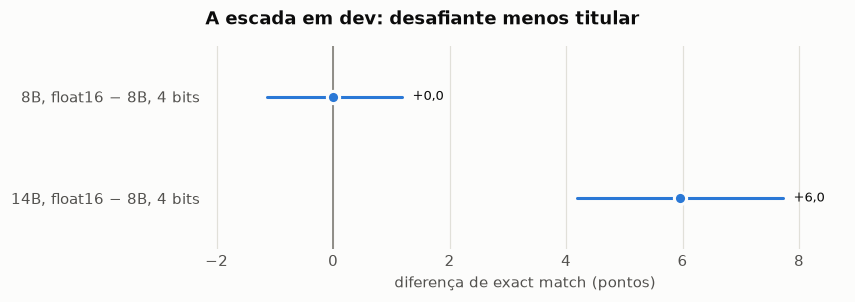

In [6]:
disputas = escolha["disputas"]
tabela_da_escada = pd.DataFrame([
    {"desafiante": NOMES[d], "titular": CURTOS[x["contra"]], "exact match do titular": pts(x["a"]), "exact match do desafiante": pts(x["b"]),
     "diferença (intervalo de 95%)": com_intervalo(x), "toma o lugar": "sim" if x["ic_min"] > 0 else "não"}
    for d, x in disputas.items()
]).set_index("desafiante")
display(tabela_da_escada)

fig, ax = visual.diferencas_com_intervalo(
    {f"{CURTOS[d]} − {CURTOS[x['contra']]}": (100 * x["diferenca"], 100 * x["ic_min"], 100 * x["ic_max"]) for d, x in disputas.items()},
    "A escada em dev: desafiante menos titular", "diferença de exact match (pontos)",
)
visual.salvar(fig, ENTREGAS / etapa11a.ETAPA, "escada_em_dev")

sem_4_bits, maior = disputas[CANDIDATOS[0]], disputas[CANDIDATOS[1]]
display(Markdown(f"""
**Leitura.** Tirar os 4 bits não muda o exact match em `dev`: {com_intervalo(sem_4_bits)} pontos, com o zero dentro do intervalo. O titular continua o mesmo. O modelo maior acrescenta {com_intervalo(maior)} pontos sobre o titular, com o intervalo todo acima de zero: **o professor aberto passa a ser o {NOMES[escolhido]}**.
"""))

## 5. A qualidade dos professores

A decisão saiu de `dev`. O teste só é relatado. O professor fechado da Etapa 5a entra como referência: é com ele que o cenário B se compara.

In [7]:
def tabela_de_qualidade(particao, sistemas=(*ESCADA, FECHADO)):
    return pd.DataFrame({
        NOMES[s]: {qualidade.NOMES[metrica]: valor_com_intervalo(medida(s, particao, metrica)) for metrica in qualidade.METRICAS}
        for s in sistemas
    }).T

for particao, titulo in (("dev", "dev (decide)"), ("test", "teste (só relato)")):
    display(Markdown(f"**Qualidade em {titulo}**, com intervalo de 95%"))
    display(tabela_de_qualidade(particao))

**Qualidade em dev (decide)**, com intervalo de 95%

,Acurácia de intenção,Macro-F1 de intenção,F1 de entidades,Exact match
"Qwen3-8B em 4 bits (RTX 3080 local, Etapa 5b)","77,4 (75,7 a 79,2)","78,3 (75,9 a 80,6)","58,0 (55,9 a 60,1)","43,2 (41,0 a 45,3)"
"Qwen3-8B sem os 4 bits, em float16 (Colab, L4)","77,9 (76,2 a 79,7)","78,4 (76,0 a 80,8)","57,8 (55,7 a 60,0)","43,2 (41,0 a 45,5)"
"Qwen3-14B sem os 4 bits, em float16 (Colab, A100)","80,6 (79,0 a 82,3)","81,6 (79,4 a 83,9)","62,4 (60,4 a 64,6)","49,1 (47,0 a 51,5)"
"Claude Haiku 5.5 (professor fechado, Etapa 5a)","84,1 (82,6 a 85,6)","84,4 (82,4 a 86,4)","68,5 (66,5 a 70,5)","54,7 (52,6 a 57,0)"


**Qualidade em teste (só relato)**, com intervalo de 95%

,Acurácia de intenção,Macro-F1 de intenção,F1 de entidades,Exact match
"Qwen3-8B em 4 bits (RTX 3080 local, Etapa 5b)","77,6 (76,1 a 79,1)","76,6 (74,7 a 79,2)","55,7 (53,9 a 57,4)","43,2 (41,5 a 45,0)"
"Qwen3-8B sem os 4 bits, em float16 (Colab, L4)","77,9 (76,5 a 79,4)","76,9 (74,9 a 79,5)","56,5 (54,8 a 58,2)","43,4 (41,6 a 45,2)"
"Qwen3-14B sem os 4 bits, em float16 (Colab, A100)","80,0 (78,6 a 81,4)","78,7 (76,8 a 81,3)","61,4 (59,6 a 63,1)","49,0 (46,9 a 50,7)"
"Claude Haiku 5.5 (professor fechado, Etapa 5a)","83,5 (82,1 a 84,7)","82,1 (80,3 a 84,7)","66,1 (64,5 a 67,7)","54,0 (52,3 a 55,7)"


**Comparações pareadas no teste** (B − A, em pontos, com intervalo de 95%)

,Acurácia de intenção,Macro-F1 de intenção,F1 de entidades,Exact match
"8B, float16 − 8B, 4 bits","+0,3 (−0,3 a +1,0)","+0,3 (−0,5 a +1,1)","+0,8 (−0,2 a +1,8)","+0,2 (−0,8 a +1,2)"
"14B, float16 − 8B, 4 bits","+2,4 (+1,3 a +3,6)","+2,1 (+0,6 a +3,5)","+5,7 (+4,3 a +7,1)","+5,7 (+4,2 a +7,3)"
"14B, float16 − 8B, float16","+2,1 (+1,0 a +3,1)","+1,8 (+0,5 a +3,1)","+5,0 (+3,6 a +6,3)","+5,5 (+4,1 a +7,0)"
"8B, 4 bits − Claude Haiku 5.5","−5,9 (−7,2 a −4,5)","−5,5 (−7,2 a −3,8)","−10,4 (−11,9 a −8,9)","−10,8 (−12,4 a −9,1)"
"8B, float16 − Claude Haiku 5.5","−5,5 (−6,8 a −4,2)","−5,3 (−6,9 a −3,6)","−9,6 (−11,1 a −8,1)","−10,6 (−12,2 a −9,0)"
"14B, float16 − Claude Haiku 5.5","−3,4 (−4,5 a −2,3)","−3,4 (−5,1 a −1,8)","−4,6 (−6,1 a −3,3)","−5,1 (−6,7 a −3,5)"



**Leitura.** No teste o quadro é o mesmo de `dev`. Sem os 4 bits: +0,2 (−0,8 a +1,2) pontos de exact match. Com o modelo maior: +5,7 (+4,2 a +7,3). A distância do professor aberto para o fechado cai de −10,8 (−12,4 a −9,1) para −5,1 (−6,7 a −3,5) pontos: o modelo maior recupera cerca de 53% da distância, e o que sobra continua distinguível de zero.


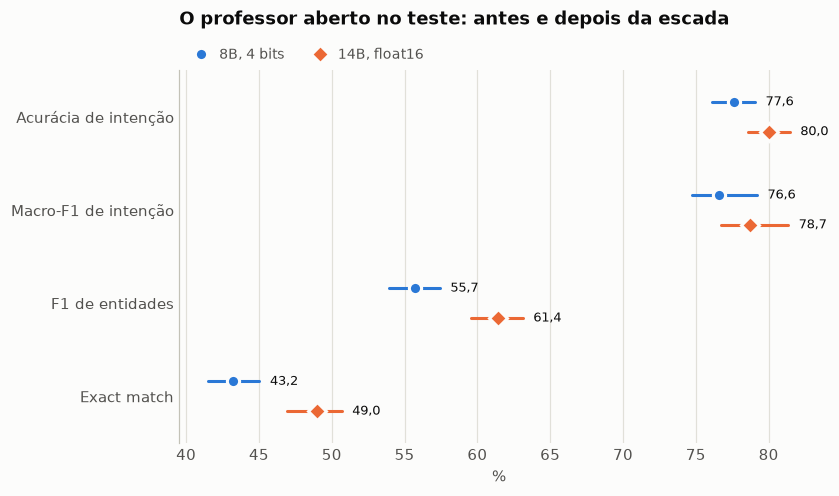

In [8]:
def tabela_de_comparacoes(particao, da_extensao=False):
    linhas = comp[(comp["particao"] == particao) & ((comp["b"] == EXTENSAO) == da_extensao)]
    return pd.DataFrame({
        qualidade.NOMES[metrica]: {linha["comparacao"]: com_intervalo(linha) for _, linha in linhas[linhas["metrica"] == metrica].iterrows()}
        for metrica in qualidade.METRICAS
    })

display(Markdown("**Comparações pareadas no teste** (B − A, em pontos, com intervalo de 95%)"))
display(tabela_de_comparacoes("test"))

serie = lambda s: {qualidade.NOMES[metrica]: tuple(100 * medida(s, "test", metrica)[k] for k in ("valor", "ic_min", "ic_max")) for metrica in qualidade.METRICAS}
fig, ax = visual.pontos_com_intervalo({CURTOS[ESCADA[0]]: serie(ESCADA[0]), CURTOS[escolhido]: serie(escolhido)}, "O professor aberto no teste: antes e depois da escada", "%")
visual.salvar(fig, ENTREGAS / etapa11a.ETAPA, "professor_aberto_no_teste")

antes, depois = comparacao(ESCADA[0], FECHADO, "test"), comparacao(escolhido, FECHADO, "test")
sem_bits_no_teste, maior_no_teste = comparacao(CANDIDATOS[0], ESCADA[0], "test"), comparacao(CANDIDATOS[1], ESCADA[0], "test")
recuperado = 1 - depois["diferenca"] / antes["diferenca"]
display(Markdown(f"""
**Leitura.** No teste o quadro é o mesmo de `dev`. Sem os 4 bits: {com_intervalo(sem_bits_no_teste)} pontos de exact match. Com o modelo maior: {com_intervalo(maior_no_teste)}. A distância do professor aberto para o fechado cai de {com_intervalo(antes)} para {com_intervalo(depois)} pontos: o modelo maior recupera cerca de {pts(recuperado, 0)}% da distância, e o que sobra continua distinguível de zero.
"""))

## 6. O que muda nos rótulos que o aluno recebe

Descritivo, fora da regra. O aluno aprende do treino rotulado pelo professor. Três perguntas: quão bons são esses rótulos, quanto eles mudam de um professor para outro, e quantas respostas a leitura não aproveita.

In [9]:
display(Markdown("**Qualidade dos rótulos do treino** (contra os rótulos humanos, que o aluno nunca vê), com intervalo de 95%"))
display(tabela_de_qualidade("train"))

quanto_muda = mud[(mud["particao"] == "train") & (mud["b"] != EXTENSAO)].set_index("comparacao")[["mesma_intencao", "mesmas_entidades", "mesma_resposta_lida", "mesmo_texto_bruto"]]
display(Markdown(f"**Quanto as respostas do treino coincidem entre dois professores** ({n(len(treino))} pedidos)"))
display(quanto_muda.map(lambda x: pts(x) + "%").rename(columns={"mesma_intencao": "mesma intenção", "mesmas_entidades": "mesmas entidades", "mesma_resposta_lida": "mesma resposta, depois de lida", "mesmo_texto_bruto": "mesmo texto bruto"}))

nomes_das_contagens = {"json_invalido": "JSON inválido", "sem_rotulo_aproveitavel": "sem rótulo aproveitável", "entidades": "entidades devolvidas", "tipo_fora_da_lista": "tipo fora da lista",
                       "texto_nao_encontrado": "texto não encontrado no pedido", "cortadas_no_limite_de_tokens": "cortadas no limite de tokens"}
leitura = diag[diag["versao"].isin(ESCADA)].assign(professor=diag["versao"].map(CURTOS)).set_index(["professor", "particao"])[
    ["pedidos", "json_invalido", "sem_rotulo_aproveitavel", "entidades", "tipo_fora_da_lista", "texto_nao_encontrado", "cortadas_no_limite_de_tokens"]
].rename(columns={"json_invalido": "JSON inválido", "sem_rotulo_aproveitavel": "sem rótulo aproveitável", "entidades": "entidades devolvidas",
                  "tipo_fora_da_lista": "tipo fora da lista", "texto_nao_encontrado": "texto não encontrado no pedido", "cortadas_no_limite_de_tokens": "cortadas no limite de tokens"})
display(Markdown("**Diagnósticos de leitura das respostas** (contagens)"))
display(leitura)

par_8b = quanto_muda.loc[f"{CURTOS[CANDIDATOS[0]]} e {CURTOS[ESCADA[0]]}"]
par_14b = quanto_muda.loc[f"{CURTOS[CANDIDATOS[1]]} e {CURTOS[ESCADA[0]]}"]
d_treino = diag[diag["particao"] == "train"].set_index("versao")
display(Markdown(f"""
**Leitura.**

- Tirar os 4 bits muda bastante resposta sem mudar a qualidade: no treino, só {pts(par_8b['mesma_resposta_lida'])}% das respostas das duas versões do 8B coincidem (a troca de máquina, sozinha, explicaria {pts(muda_com_a_maquina, 0)}% de mudança), e o exact match dos rótulos fica em {pts(medida(ESCADA[0], 'train')['valor'])}% e {pts(medida(CANDIDATOS[0], 'train')['valor'])}%. As respostas trocam de lugar: erros somem e outros aparecem na mesma medida.
- O modelo maior concorda com o titular em {pts(par_14b['mesma_resposta_lida'])}% das respostas do treino, e os rótulos dele têm exact match de {pts(medida(CANDIDATOS[1], 'train')['valor'])}%.
- A leitura aproveita mais: entidades com tipo fora da lista no treino caem de {n(d_treino.loc[ESCADA[0], 'tipo_fora_da_lista'])} para {n(d_treino.loc[CANDIDATOS[0], 'tipo_fora_da_lista'])} (sem os 4 bits) e {n(d_treino.loc[CANDIDATOS[1], 'tipo_fora_da_lista'])} (modelo maior); respostas com JSON inválido, de {n(d_treino.loc[ESCADA[0], 'json_invalido'])} para {n(d_treino.loc[CANDIDATOS[0], 'json_invalido'])} e {n(d_treino.loc[CANDIDATOS[1], 'json_invalido'])}.
"""))

**Qualidade dos rótulos do treino** (contra os rótulos humanos, que o aluno nunca vê), com intervalo de 95%

,Acurácia de intenção,Macro-F1 de intenção,F1 de entidades,Exact match
"Qwen3-8B em 4 bits (RTX 3080 local, Etapa 5b)","77,8 (77,1 a 78,6)","76,5 (75,5 a 77,5)","57,2 (56,3 a 58,1)","43,6 (42,7 a 44,5)"
"Qwen3-8B sem os 4 bits, em float16 (Colab, L4)","78,5 (77,7 a 79,2)","76,5 (75,5 a 77,6)","57,8 (56,9 a 58,7)","44,1 (43,1 a 45,0)"
"Qwen3-14B sem os 4 bits, em float16 (Colab, A100)","79,9 (79,1 a 80,6)","78,2 (77,2 a 79,2)","61,4 (60,5 a 62,2)","48,2 (47,3 a 49,1)"
"Claude Haiku 5.5 (professor fechado, Etapa 5a)","84,2 (83,6 a 84,9)","82,1 (81,2 a 83,1)","67,5 (66,7 a 68,3)","53,6 (52,8 a 54,5)"


**Quanto as respostas do treino coincidem entre dois professores** (11.514 pedidos)

,mesma intenção,mesmas entidades,"mesma resposta, depois de lida",mesmo texto bruto
comparacao,,,,
"8B, float16 e 8B, 4 bits","92,7%","76,8%","73,7%","72,1%"
"14B, float16 e 8B, 4 bits","84,2%","61,6%","55,6%","53,5%"
"14B, float16 e 8B, float16","85,1%","62,0%","56,5%","54,8%"


**Diagnósticos de leitura das respostas** (contagens)

pedidos  JSON inválido  sem rótulo aproveitável  \
professor    particao                                                    
8B, 4 bits   dev          2033              0                        0   
             test         2974              7                        7   
             train       11514             11                       11   
8B, float16  dev          2033              0                        0   
             test         2974              0                        0   
             train       11514              1                        1   
14B, float16 dev          2033              0                        0   
             test         2974              0                        0   
             train       11514              0                        0   

                       entidades devolvidas  tipo fora da lista  \
professor    particao                                             
8B, 4 bits   dev                       2489                  92   
             test                      3515                 119   
             train                    14046                 532   
8B, float16  dev                       2492                  67   
             test                      3563                 116   
             train                    14070                 412   
14B, float16 dev                       2346                  21   
             test                      3299                  36   
             train                    13151                 112   

                       texto não encontrado no pedido  \
professor    particao                                   
8B, 4 bits   dev                                   52   
             test                                  86   
             train                                259   
8B, float16  dev                                   36   
             test                                  63   
             train                                206   
14B, float16 dev                                   22   
             test                                  17   
             train                                104   

                       cortadas no limite de tokens  
professor    particao                                
8B, 4 bits   dev                                  0  
             test                                 0  
             train                                0  
8B, float16  dev                                  0  
             test                                 0  
             train                                0  
14B, float16 dev                                  0  
             test                                 0  
             train                                0


**Leitura.**

- Tirar os 4 bits muda bastante resposta sem mudar a qualidade: no treino, só 73,7% das respostas das duas versões do 8B coincidem (a troca de máquina, sozinha, explicaria 4% de mudança), e o exact match dos rótulos fica em 43,6% e 44,1%. As respostas trocam de lugar: erros somem e outros aparecem na mesma medida.
- O modelo maior concorda com o titular em 55,6% das respostas do treino, e os rótulos dele têm exact match de 48,2%.
- A leitura aproveita mais: entidades com tipo fora da lista no treino caem de 532 para 412 (sem os 4 bits) e 112 (modelo maior); respostas com JSON inválido, de 11 para 1 e 0.


## 7. Tempo e custo

O Colab cobra em unidades de computação, por hora de sessão ligada. As duas rodadas longas correram ao mesmo tempo, e o saldo é da conta inteira: o que cada condutor mediu pela diferença de saldo inclui o gasto da outra sessão. Por isso o custo é repartido por **taxa × tempo** de cada sessão e depois posto na escala do que a conta de fato cobrou.

In [10]:
tabela_do_custo = pd.DataFrame([
    {"trecho": p["o_que"], "placa": p["gpu"], "de": p["de"], "até": p["ate"], "horas": num(p["horas"], 2), "unidades por hora": num(p["taxa_por_hora"], 2),
     "taxa × tempo": num(p["unidades"], 2), "fechado na conta": num(p["unidades_fechadas_na_conta"], 2)}
    for p in custos["partes"]
]).set_index("trecho")
display(tabela_do_custo)
conta = custos["conta"]
display(Markdown(f"""
**Leitura.** A soma por taxa × tempo dá {num(custos['soma_por_taxa_e_tempo'], 2)} unidades; a conta foi de {num(conta['saldo_antes'], 2)} para {num(conta['saldo_depois'], 2)}: **{num(conta['gasto'], 2)} unidades gastas na escada de três degraus**, em 18/11, de um teto de {custos['teto_da_etapa']} para a etapa. A diferença de {num(abs(custos['diferenca_entre_a_soma_e_a_conta']), 2)} entre a soma e a conta fica registrada; o número que vale é o da conta. Os condutores tinham medido {', '.join(num(x, 2) for x in list(custos['o_que_os_condutores_mediram_pelo_saldo'].values())[1:])} pelas diferenças de saldo, números que se sobrepõem.

Tempo de GPU para rotular dev, teste e treino ({n(len(dev) + len(teste) + len(treino))} pedidos): {horas(sum(versoes[CANDIDATOS[0]]['tempos']['segundos_de_gpu'].values()))} no {CURTOS[CANDIDATOS[0]]} ({versoes[CANDIDATOS[0]]['gpu']['placa']}) e {horas(sum(versoes[CANDIDATOS[1]]['tempos']['segundos_de_gpu'].values()))} no {CURTOS[CANDIDATOS[1]]} ({versoes[CANDIDATOS[1]]['gpu']['placa']}). Na máquina local, em 4 bits, tinham sido {horas(sum(versoes[ESCADA[0]]['execucao']['segundos_de_gpu'].values()))}.
"""))

,placa,de,até,horas,unidades por hora,taxa × tempo,fechado na conta
trecho,,,,,,,
"conferência de ambiente (4 bits na L4), do começo da sessão até o candidato 1 assumi-la",L4,17:19:09,17:26:24,"0,12","1,94","0,23","0,23"
"candidato 1: precisão, dev, teste e treino",L4,17:26:24,21:03:40,"3,62","1,94","7,02","6,87"
"candidato 2: precisão, dev, teste e treino",A100,17:23:29,19:40:41,"2,29","6,73","15,39","15,06"
"sonda da A100, até o condutor do candidato 2 assumir a sessão",A100,17:19:01,17:23:29,"0,07","6,73","0,50","0,49"
"sonda da L4 (máquina, kernel que segue sem a ligação local, desligamento pela própria VM)",L4,17:08:43,17:10:35,"0,03","1,94","0,06","0,06"
sonda da G4 (placa e taxa),G4,17:23:40,17:24:28,"0,01","10,05","0,13","0,13"



**Leitura.** A soma por taxa × tempo dá 23,33 unidades; a conta foi de 600,00 para 577,17: **22,83 unidades gastas na escada de três degraus**, em 18/11, de um teto de 150 para a etapa. A diferença de 0,50 entre a soma e a conta fica registrada; o número que vale é o da conta. Os condutores tinham medido 22,09, 20,22 pelas diferenças de saldo, números que se sobrepõem.

Tempo de GPU para rotular dev, teste e treino (16.521 pedidos): 3 h 33 min no 8B, float16 (NVIDIA L4) e 2 h 12 min no 14B, float16 (NVIDIA A100-SXM4-40GB). Na máquina local, em 4 bits, tinham sido 2 h 34 min.


## 8. Extensão, decidida depois: o Qwen3-32B

**Esta seção não estava no plano.** As regras das 17h16 de 18/11 previam dois degraus novos. Depois de ver o resultado deles (seções 4 e 5: o 14B tomou o lugar do 8B e ainda ficou abaixo do professor fechado), decidiu-se rodar mais um degrau, o Qwen3-32B, na placa de 96 GB do Colab.

Um degrau acrescentado depois de ver o resultado é uma segunda olhada nos mesmos dados de `dev`. Por isso:

- a regra é a mesma, gravada num arquivo próprio (`regra_extensao_32b.json`) antes de a rodada começar, e o arquivo diz o que já se sabia quando foi escrito;
- o resultado é relatado aqui, separado da escada planejada; `regra.json` e `escolha.json` não mudam;
- o 32B rotulou dev, teste e treino inteiros, ganhasse ou perdesse, e a versão fica guardada.

In [11]:
inicio_da_extensao = versoes[EXTENSAO]["conducoes"][0]["inicio"]
regra_ext_veio_antes = regra_ext["escrita_em"] < inicio_da_extensao
print(f"Regra da extensão gravada em {regra_ext['escrita_em']}; primeiro lançamento do condutor em {inicio_da_extensao}. Regra antes da rodada: {'sim' if regra_ext_veio_antes else 'NÃO'}")
display(pd.Series({
    "o que já se sabia ao escrever": regra_ext["o_que_ja_se_sabia"],
    "autorização": regra_ext["autorizacao"],
    "regra": regra_ext["regra"],
    "titular e desafiante": f"{NOMES[regra_ext['titular']]} e {NOMES[regra_ext['desafiante']]}",
    "precisão": f"{versoes[EXTENSAO]['precisao']['tipo_das_contas_do_professor']}; pontuações não finitas na conferência: " + str(json.loads((etapa11a.PASTA / EXTENSAO / 'precisao.json').read_text(encoding='utf-8'))['pontuacoes_nao_finitas']),
}).rename("regra da extensão").to_frame())

Regra da extensão gravada em 2026-11-18 22:09:00 -0300; primeiro lançamento do condutor em 2026-11-18 22:09:24 -0300. Regra antes da rodada: sim


,regra da extensão
o que já se sabia ao escrever,"esta extensão NÃO estava nas regras das 17h16. Foi decidida depois de ver o resultado da escada de três degraus (em dev, o Qwen3-14B tomou o lugar do Qwen3-8B; no teste, ele ficou abaixo do profes..."
autorização,"do usuário, em 18/11/2026 perto das 22h, com custo previsto de cerca de 40 unidades. Ela chegou a esta rodada pela mensagem do orquestrador; o agente que preparou e lançou a rodada não falou com o..."
regra,do mais barato para o mais caro; um candidato mais caro só toma o lugar se o exact match em dev for distinguivelmente maior (IC95 da diferença pareada acima de zero)
titular e desafiante,"Qwen3-14B sem os 4 bits, em float16 (Colab, A100) e Qwen3-32B sem os 4 bits, em float16 (Colab, G4)"
precisão,torch.float16; pontuações não finitas na conferência: 0


,titular,exact match do titular,exact match do desafiante,diferença em dev (intervalo de 95%),toma o lugar,diferença no teste (só relato)
desafiante,,,,,,
"Qwen3-32B sem os 4 bits, em float16 (Colab, G4)","14B, float16","49,1","49,1","−0,05 (−1,62 a +1,72)",não,"+1,04 (−0,30 a +2,46)"


**Qualidade em dev (decide)**, com intervalo de 95%

,Acurácia de intenção,Macro-F1 de intenção,F1 de entidades,Exact match
"Qwen3-8B em 4 bits (RTX 3080 local, Etapa 5b)","77,4 (75,7 a 79,2)","78,3 (75,9 a 80,6)","58,0 (55,9 a 60,1)","43,2 (41,0 a 45,3)"
"Qwen3-8B sem os 4 bits, em float16 (Colab, L4)","77,9 (76,2 a 79,7)","78,4 (76,0 a 80,8)","57,8 (55,7 a 60,0)","43,2 (41,0 a 45,5)"
"Qwen3-14B sem os 4 bits, em float16 (Colab, A100)","80,6 (79,0 a 82,3)","81,6 (79,4 a 83,9)","62,4 (60,4 a 64,6)","49,1 (47,0 a 51,5)"
"Qwen3-32B sem os 4 bits, em float16 (Colab, G4)","81,0 (79,4 a 82,7)","80,8 (78,8 a 83,2)","63,3 (61,3 a 65,4)","49,1 (47,0 a 51,4)"
"Claude Haiku 5.5 (professor fechado, Etapa 5a)","84,1 (82,6 a 85,6)","84,4 (82,4 a 86,4)","68,5 (66,5 a 70,5)","54,7 (52,6 a 57,0)"


**Qualidade em teste (só relato)**, com intervalo de 95%

,Acurácia de intenção,Macro-F1 de intenção,F1 de entidades,Exact match
"Qwen3-8B em 4 bits (RTX 3080 local, Etapa 5b)","77,6 (76,1 a 79,1)","76,6 (74,7 a 79,2)","55,7 (53,9 a 57,4)","43,2 (41,5 a 45,0)"
"Qwen3-8B sem os 4 bits, em float16 (Colab, L4)","77,9 (76,5 a 79,4)","76,9 (74,9 a 79,5)","56,5 (54,8 a 58,2)","43,4 (41,6 a 45,2)"
"Qwen3-14B sem os 4 bits, em float16 (Colab, A100)","80,0 (78,6 a 81,4)","78,7 (76,8 a 81,3)","61,4 (59,6 a 63,1)","49,0 (46,9 a 50,7)"
"Qwen3-32B sem os 4 bits, em float16 (Colab, G4)","80,9 (79,4 a 82,3)","80,1 (78,2 a 82,8)","62,5 (60,8 a 64,3)","50,0 (48,2 a 51,8)"
"Claude Haiku 5.5 (professor fechado, Etapa 5a)","83,5 (82,1 a 84,7)","82,1 (80,3 a 84,7)","66,1 (64,5 a 67,7)","54,0 (52,3 a 55,7)"


**Qualidade em rótulos do treino, contra os humanos (descritivo)**, com intervalo de 95%

,Acurácia de intenção,Macro-F1 de intenção,F1 de entidades,Exact match
"Qwen3-8B em 4 bits (RTX 3080 local, Etapa 5b)","77,8 (77,1 a 78,6)","76,5 (75,5 a 77,5)","57,2 (56,3 a 58,1)","43,6 (42,7 a 44,5)"
"Qwen3-8B sem os 4 bits, em float16 (Colab, L4)","78,5 (77,7 a 79,2)","76,5 (75,5 a 77,6)","57,8 (56,9 a 58,7)","44,1 (43,1 a 45,0)"
"Qwen3-14B sem os 4 bits, em float16 (Colab, A100)","79,9 (79,1 a 80,6)","78,2 (77,2 a 79,2)","61,4 (60,5 a 62,2)","48,2 (47,3 a 49,1)"
"Qwen3-32B sem os 4 bits, em float16 (Colab, G4)","81,1 (80,4 a 81,8)","79,5 (78,5 a 80,4)","62,3 (61,5 a 63,1)","48,7 (47,8 a 49,7)"
"Claude Haiku 5.5 (professor fechado, Etapa 5a)","84,2 (83,6 a 84,9)","82,1 (81,2 a 83,1)","67,5 (66,7 a 68,3)","53,6 (52,8 a 54,5)"


**Comparações pareadas da extensão** (B − A, em pontos, com intervalo de 95%): dev e teste

Acurácia de intenção  \
dev   32B, float16 − 14B, float16       +0,4 (−0,8 a +1,7)   
      32B, float16 − 8B, 4 bits         +3,6 (+2,2 a +5,0)   
      32B, float16 − Claude Haiku 5.5   −3,1 (−4,4 a −1,8)   
teste 32B, float16 − 14B, float16       +0,8 (−0,1 a +1,8)   
      32B, float16 − 8B, 4 bits         +3,3 (+2,1 a +4,4)   
      32B, float16 − Claude Haiku 5.5   −2,6 (−3,7 a −1,5)   

                                      Macro-F1 de intenção  \
dev   32B, float16 − 14B, float16       −0,8 (−2,4 a +1,1)   
      32B, float16 − 8B, 4 bits         +2,6 (+0,7 a +4,6)   
      32B, float16 − Claude Haiku 5.5   −3,6 (−5,2 a −1,7)   
teste 32B, float16 − 14B, float16       +1,4 (+0,1 a +2,9)   
      32B, float16 − 8B, 4 bits         +3,5 (+2,0 a +5,0)   
      32B, float16 − Claude Haiku 5.5   −2,0 (−3,6 a −0,6)   

                                          F1 de entidades         Exact match  
dev   32B, float16 − 14B, float16      +0,9 (−0,6 a +2,4)  −0,0 (−1,6 a +1,7)  
      32B, float16 − 8B, 4 bits        +5,3 (+3,6 a +7,1)  +5,9 (+4,2 a +7,8)  
      32B, float16 − Claude Haiku 5.5  −5,2 (−6,9 a −3,5)  −5,7 (−7,5 a −3,7)  
teste 32B, float16 − 14B, float16      +1,1 (−0,1 a +2,4)  +1,0 (−0,3 a +2,5)  
      32B, float16 − 8B, 4 bits        +6,9 (+5,4 a +8,3)  +6,8 (+5,2 a +8,3)  
      32B, float16 − Claude Haiku 5.5  −3,5 (−5,0 a −2,2)  −4,0 (−5,6 a −2,5)

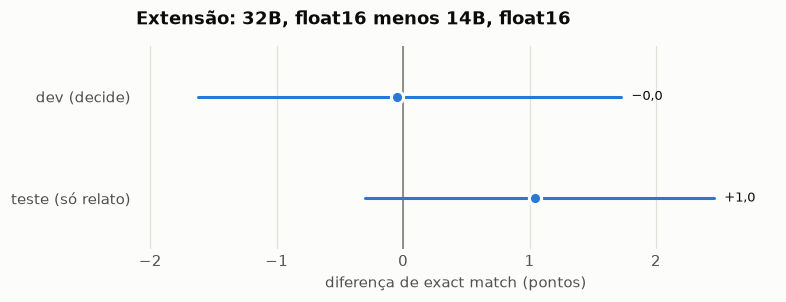

In [12]:
ext = escolha_ext["disputas"][EXTENSAO]
ext_no_teste = comparacao(EXTENSAO, TITULAR_DA_EXTENSAO, "test")
toma_o_lugar = ext["ic_min"] > 0
display(pd.DataFrame([{
    "desafiante": NOMES[EXTENSAO], "titular": CURTOS[ext["contra"]], "exact match do titular": pts(ext["a"]), "exact match do desafiante": pts(ext["b"]),
    "diferença em dev (intervalo de 95%)": com_intervalo(ext, 2), "toma o lugar": "sim" if toma_o_lugar else "não",
    "diferença no teste (só relato)": com_intervalo(ext_no_teste, 2),
}]).set_index("desafiante"))

fig, ax = visual.diferencas_com_intervalo(
    {"dev (decide)": (100 * ext["diferenca"], 100 * ext["ic_min"], 100 * ext["ic_max"]),
     "teste (só relato)": tuple(100 * ext_no_teste[k] for k in ("diferenca", "ic_min", "ic_max"))},
    f"Extensão: {CURTOS[EXTENSAO]} menos {CURTOS[TITULAR_DA_EXTENSAO]}", "diferença de exact match (pontos)",
)
visual.salvar(fig, ENTREGAS / etapa11a.ETAPA, "extensao_32b")

for particao, titulo in (("dev", "dev (decide)"), ("test", "teste (só relato)"), ("train", "rótulos do treino, contra os humanos (descritivo)")):
    display(Markdown(f"**Qualidade em {titulo}**, com intervalo de 95%"))
    display(tabela_de_qualidade(particao, (*ESCADA, EXTENSAO, FECHADO)))
display(Markdown("**Comparações pareadas da extensão** (B − A, em pontos, com intervalo de 95%): dev e teste"))
display(pd.concat({"dev": tabela_de_comparacoes("dev", da_extensao=True), "teste": tabela_de_comparacoes("test", da_extensao=True)}))

In [13]:
muda_na_extensao = mud[(mud["particao"] == "train") & (mud["b"] == EXTENSAO)].set_index("comparacao")[["mesma_intencao", "mesmas_entidades", "mesma_resposta_lida", "mesmo_texto_bruto"]]
display(Markdown(f"**Quanto as respostas do treino do 32B coincidem com as de outros professores** ({n(len(treino))} pedidos)"))
display(muda_na_extensao.map(lambda x: pts(x) + "%").rename(columns={"mesma_intencao": "mesma intenção", "mesmas_entidades": "mesmas entidades", "mesma_resposta_lida": "mesma resposta, depois de lida", "mesmo_texto_bruto": "mesmo texto bruto"}))
display(Markdown("**Diagnósticos de leitura** (contagens), titular e desafiante"))
display(diag[diag["versao"].isin((TITULAR_DA_EXTENSAO, EXTENSAO))].assign(professor=lambda t: t["versao"].map(CURTOS)).set_index(["professor", "particao"])[["pedidos", *nomes_das_contagens]].rename(columns=nomes_das_contagens))

custo_ext, total = custos["extensao_32b"], custos["total_no_colab"]
parte_ext = custo_ext["partes"][0]
com_o_titular = muda_na_extensao.loc[f"{CURTOS[EXTENSAO]} e {CURTOS[TITULAR_DA_EXTENSAO]}"]
fechado_ext = comparacao(EXTENSAO, FECHADO, "test")
display(Markdown(f"""
**Leitura.**

- **A disputa.** Em `dev`, o {NOMES[EXTENSAO]} fica a {com_intervalo(ext, 2)} pontos de exact match do titular, com o zero {'fora' if toma_o_lugar or ext['ic_max'] < 0 else 'dentro'} do intervalo: **{'toma o lugar' if toma_o_lugar else 'não toma o lugar'}**. O professor aberto {'passa a ser' if final != escolhido else 'continua sendo'} o {NOMES[final]}.
- **No teste**, só para relato: {com_intervalo(ext_no_teste, 2)} pontos sobre o titular, e {com_intervalo(fechado_ext)} em relação ao professor fechado.
- **Os rótulos do treino** do 32B têm exact match de {pts(medida(EXTENSAO, 'train')['valor'])}% contra os humanos ({pts(medida(TITULAR_DA_EXTENSAO, 'train')['valor'])}% no titular). As respostas dos dois coincidem em {pts(com_o_titular['mesma_resposta_lida'])}% do treino, e a intenção em {pts(com_o_titular['mesma_intencao'])}%.
- **Custo.** A sessão da G4 ficou ligada {num(parte_ext['horas'], 2)} h ({parte_ext['de']} às {parte_ext['ate']}); por taxa × tempo seriam {num(custo_ext['soma_por_taxa_e_tempo'], 2)} unidades, e a conta cobrou **{num(custo_ext['conta']['gasto'], 2)}** (de {num(custo_ext['conta']['saldo_antes'], 2)} para {num(custo_ext['conta']['saldo_depois'], 2)}). Depois de `dev`, o condutor projetou {num(custo_ext['projecao_depois_de_dev']['unidades_projetadas'], 1)} unidades para a rodada inteira (teto {custo_ext['teto_do_condutor']}) e deixou seguir. O modelo ocupa {num(versoes[EXTENSAO]['gpu']['vram_do_modelo_gb'], 1)} GB na placa (pico de {num(versoes[EXTENSAO]['gpu']['vram_de_pico_gb'], 1)} GB) e levou {num(sum(versoes[EXTENSAO]['tempos']['segundos_de_gpu'].values()) / sum(versoes[EXTENSAO]['execucao']['pedidos'].values()), 2)} s por pedido.
- **Total do Colab no projeto:** de {num(total['saldo_antes'], 2)} para {num(total['saldo_depois'], 2)}, **{num(total['gasto'], 2)} unidades**.
"""))

**Quanto as respostas do treino do 32B coincidem com as de outros professores** (11.514 pedidos)

,mesma intenção,mesmas entidades,"mesma resposta, depois de lida",mesmo texto bruto
comparacao,,,,
"32B, float16 e 14B, float16","87,8%","68,7%","63,3%","62,2%"
"32B, float16 e 8B, 4 bits","83,9%","59,6%","53,9%","52,0%"


**Diagnósticos de leitura** (contagens), titular e desafiante

pedidos  JSON inválido  sem rótulo aproveitável  \
professor    particao                                                    
14B, float16 dev          2033              0                        0   
             test         2974              0                        0   
             train       11514              0                        0   
32B, float16 dev          2033              1                        1   
             test         2974              0                        0   
             train       11514              1                        1   

                       entidades devolvidas  tipo fora da lista  \
professor    particao                                             
14B, float16 dev                       2346                  21   
             test                      3299                  36   
             train                    13151                 112   
32B, float16 dev                       2358                  20   
             test                      3319                  19   
             train                    13274                 103   

                       texto não encontrado no pedido  \
professor    particao                                   
14B, float16 dev                                   22   
             test                                  17   
             train                                104   
32B, float16 dev                                    9   
             test                                  11   
             train                                 77   

                       cortadas no limite de tokens  
professor    particao                                
14B, float16 dev                                  0  
             test                                 0  
             train                                0  
32B, float16 dev                                  0  
             test                                 0  
             train                                0


**Leitura.**

- **A disputa.** Em `dev`, o Qwen3-32B sem os 4 bits, em float16 (Colab, G4) fica a −0,05 (−1,62 a +1,72) pontos de exact match do titular, com o zero dentro do intervalo: **não toma o lugar**. O professor aberto continua sendo o Qwen3-14B sem os 4 bits, em float16 (Colab, A100).
- **No teste**, só para relato: +1,04 (−0,30 a +2,46) pontos sobre o titular, e −4,0 (−5,6 a −2,5) em relação ao professor fechado.
- **Os rótulos do treino** do 32B têm exact match de 48,7% contra os humanos (48,2% no titular). As respostas dos dois coincidem em 63,3% do treino, e a intenção em 87,8%.
- **Custo.** A sessão da G4 ficou ligada 2,48 h (22:25:24 às 00:54:02); por taxa × tempo seriam 24,90 unidades, e a conta cobrou **24,15** (de 577,17 para 553,02). Depois de `dev`, o condutor projetou 25,8 unidades para a rodada inteira (teto 60) e deixou seguir. O modelo ocupa 65,5 GB na placa (pico de 69,4 GB) e levou 0,51 s por pedido.
- **Total do Colab no projeto:** de 600,00 para 553,02, **46,98 unidades**.


## 9. Entrega

A entrega é montada a partir das pastas das versões. Os arquivos grandes entram como links físicos: aparecem na entrega sem ocupar o disco duas vezes, e nada sai do cache.

Para um aluno usar outro professor, basta trocar o caminho: `etapa6.PROFESSORES["aberto"] = etapa11a.como_professor(versão)`. A célula abaixo faz essa troca e lê os arquivos com as funções da Etapa 6, as mesmas que a Etapa 10a usa.

In [14]:
PASTA = etapa11a.entregar()

original = dict(etapa6.PROFESSORES["aberto"])
consumo = {}
try:
    for v in (*CANDIDATOS, EXTENSAO):
        etapa6.PROFESSORES["aberto"] = etapa11a.como_professor(v)
        do_treino = etapa6.treino_do_professor("aberto", treino)
        do_dev = etapa6.dev_do_professor("aberto", dev, intents)
        no_teste = etapa6.previsoes_do_professor("aberto", "test", teste)
        logits = etapa6.logits_do_professor("treino", len(treino), intents)
        com_rotulo = do_treino["valido"].to_numpy()
        do_rotulo = np.array([intents.index(i) if i in intents else 0 for i in do_treino["intent"]])
        consumo[v] = {
            "pasta": str(etapa6.pasta_do_professor("aberto").relative_to(RAIZ)),
            "treino relido reproduz as respostas": [Previsao.de_tags(i, list(t)) for i, t in zip(do_treino["intent"], do_treino["tags"])] == etapa11a.previsoes(v, "train")[0],
            "a intenção de maior pontuação é a do rótulo": bool(np.all(logits[com_rotulo, do_rotulo[com_rotulo]] >= logits[com_rotulo].max(axis=1) - 1e-4)),
            "logits finitos": bool(np.isfinite(logits).all()),
            "dev e teste lidos": len(do_dev) == len(dev) and len(no_teste) == len(teste),
        }
finally:
    etapa6.PROFESSORES["aberto"] = original
pd.DataFrame(consumo).T

,pasta,treino relido reproduz as respostas,a intenção de maior pontuação é a do rótulo,logits finitos,dev e teste lidos
qwen3_8b__fp16__colab_l4,entregas/11a_professor_aberto_maior/professores/qwen3_8b__fp16__colab_l4,True,True,True,True
qwen3_14b__fp16__colab_a100,entregas/11a_professor_aberto_maior/professores/qwen3_14b__fp16__colab_a100,True,True,True,True
qwen3_32b__fp16__colab_g4,entregas/11a_professor_aberto_maior/professores/qwen3_32b__fp16__colab_g4,True,True,True,True


### Critério de pronto

In [15]:
da_5b = versoes[etapa11a.VERSAO_DA_5B]["saidas"]
intacta = all(etapa11a.sha256_do_arquivo(RAIZ / caminho) == registro["sha256"] for caminho, registro in da_5b.items())
condutor = etapa11a.sha256_do_arquivo(etapa11a.PASTA / etapa11a.CONDUTOR_QUE_RODOU)
completas = all(
    versoes[v]["modelo"]["commit"] and versoes[v]["condutor"]["sha256"] == etapa11a.sha256_do_arquivo(RAIZ / versoes[v]["condutor"]["arquivo"])
    and versoes[v]["codigo"]["sha256_do_pacote"] and all(c["situacao"] != "rodando" for c in versoes[v]["conducoes"])
    and versoes[v]["custo"]["unidades"] > 0 and versoes[v]["tempos"]["codigo_de_saida_do_trabalho"] == 0 and versoes[v]["gpu"]["placa"]
    for v in (CONFERENCIA, *CANDIDATOS, EXTENSAO)
)
assert all(versoes[v]["condutor"]["sha256"] == condutor for v in (CONFERENCIA, *CANDIDATOS))      # as três de 18/11, com o condutor daquele dia
guardada = PASTA / "versoes" / etapa11a.VERSAO_ENTREGUE_EM_1811
escolha_intacta = (etapa11a.sha256_do_arquivo(PASTA / "escolha.json") == etapa11a.sha256_do_arquivo(guardada / "escolha.json")
                   and all((guardada / nome).exists() for nome in ("RESUMO.md", "11a_professor_aberto_maior.html", "11a_professor_aberto_maior.ipynb", "manifesto.json")))
inteiros = all(int(linha["pedidos"]) == len(particoes[linha["particao"]]) and linha["sem_registro"] == 0 for _, linha in diag.iterrows())
titular = etapa11a.VERSAO_DA_5B
for desafiante, x in disputas.items():      # a regra, refeita a partir das disputas gravadas
    assert x["contra"] == titular
    titular = desafiante if x["ic_min"] > 0 else titular
pronto = pd.Series({
    "Regras gravadas antes da primeira rodada no Colab": regra_veio_antes,
    f"Troca de máquina medida e dentro do limiar ({n(m['pedidos'])} pedidos)": bool(ambiente["aprovado"]),
    "Precisão decidida pela regra, sem olhar métrica (float16, nenhuma pontuação não finita)": all(p["finito"] for p in precisoes.values()),
    f"Cada candidato rotulou dev, teste e treino inteiros ({n(len(dev) + len(teste) + len(treino))} pedidos)": inteiros,
    "Escada aplicada em dev pela regra gravada": titular == escolhido,
    "Arquivos de cada versão lidos pelo código da Etapa 6 (rótulos, logits, dev e teste)": all(all(v for k, v in c.items() if k != "pasta") for c in consumo.values()),
    "versao.json completo nas versões do Colab (commit, pacote, condutor, placa, tempos, custo)": bool(completas),
    "Nada da Etapa 5b mudou (mesmas impressões digitais das respostas, dos rótulos e dos logits)": intacta,
    "Extensão: regra própria gravada antes da rodada do 32B, dizendo que veio depois da escada de três degraus": regra_ext_veio_antes and "NÃO estava" in regra_ext["o_que_ja_se_sabia"],
    "Extensão: o 32B rotulou tudo e a disputa com o titular seguiu a regra": ext["contra"] == escolhido == regra_ext["titular"] and (final == EXTENSAO) == toma_o_lugar and escolha_ext["toma_o_lugar"] == toma_o_lugar,
    "A escolha de 18/11 não foi alterada, e a entrega de 18/11 está guardada dentro desta": escolha_intacta,
    f"Gasto do Colab dentro do teto da etapa ({num(total['gasto'], 2)} de {custos['teto_da_etapa']} unidades, com a extensão)": total["gasto"] <= custos["teto_da_etapa"],
}).map({True: "sim", False: "NÃO"}).rename("atendido").to_frame()
assert (pronto["atendido"] == "sim").all()
pronto

,atendido
Regras gravadas antes da primeira rodada no Colab,sim
Troca de máquina medida e dentro do limiar (300 pedidos),sim
"Precisão decidida pela regra, sem olhar métrica (float16, nenhuma pontuação não finita)",sim
"Cada candidato rotulou dev, teste e treino inteiros (16.521 pedidos)",sim
Escada aplicada em dev pela regra gravada,sim
"Arquivos de cada versão lidos pelo código da Etapa 6 (rótulos, logits, dev e teste)",sim
"versao.json completo nas versões do Colab (commit, pacote, condutor, placa, tempos, custo)",sim
"Nada da Etapa 5b mudou (mesmas impressões digitais das respostas, dos rótulos e dos logits)",sim
"Extensão: regra própria gravada antes da rodada do 32B, dizendo que veio depois da escada de três degraus",sim
Extensão: o 32B rotulou tudo e a disputa com o titular seguiu a regra,sim


## 10. Resposta

O resumo abaixo é gerado a partir dos números calculados neste notebook e gravado em `entregas/11a_professor_aberto_maior/RESUMO.md`.

In [16]:
para_os_alunos = escolha_ext["para_os_alunos"]
linhas_da_escada = "\n".join(
    f"| {NOMES[d]} | {CURTOS[x['contra']]} | {pts(x['a'])} | {pts(x['b'])} | {com_intervalo(x)} | {'sim' if x['ic_min'] > 0 else 'não'} |" for d, x in disputas.items())
linhas_de_qualidade = "\n".join(
    f"| {NOMES[s]} | " + " | ".join(valor_com_intervalo(medida(s, p, metrica)) for p in ("dev", "test") for metrica in ("intent_acc", "slot_f1", "exact_match")) + " |"
    for s in (*ESCADA, EXTENSAO, FECHADO))
linhas_de_comparacao = "\n".join(
    f"| {linha['comparacao']} | {com_intervalo(comparacao(linha['b'], linha['a'], 'dev'))} | {com_intervalo(linha)} |"
    for _, linha in comp[(comp["particao"] == "test") & (comp["metrica"] == "exact_match")].iterrows())
linhas_de_custo = "\n".join(f"| {p['o_que']} | {p['gpu']} | {num(p['horas'], 2)} | {num(p['unidades'], 2)} | {num(p['unidades_fechadas_na_conta'], 2)} |" for p in custos["partes"])
linhas_de_pronto = "\n".join(f"| {criterio} | {linha['atendido']} |" for criterio, linha in pronto.iterrows())

compressao_pesa = sem_4_bits["ic_min"] > 0 or sem_4_bits["ic_max"] < 0
depois_final = comparacao(final, FECHADO, "test")
recuperado_final = 1 - depois_final["diferenca"] / antes["diferenca"]
tamanho_pesa, ainda_sobra = maior["ic_min"] > 0, depois_final["ic_max"] < 0
veredito = ("As duas coisas." if tamanho_pesa and ainda_sobra else "Porque teve de caber em 10 GB." if tamanho_pesa else "Por ser aberto, até onde esta etapa mediu.")
sobre_a_compressao = ("A compressão em 4 bits pesa" if compressao_pesa else "A compressão em 4 bits não pesa") + f": tirá-la do Qwen3-8B muda o exact match em `dev` em {com_intervalo(sem_4_bits)} pontos."
sobre_o_tamanho = (f"O tamanho do modelo pesa: o **{etapa11a.descrever(CANDIDATOS[1])['nome']}**, que não caberia na placa local, acrescenta {com_intervalo(maior)} pontos em `dev`"
                   + (" e passa a ser o professor aberto." if escolhido == CANDIDATOS[1] else ", sem tomar o lugar do titular."))
sobre_a_extensao = (f"Numa **extensão decidida depois de ver esse resultado**, o {etapa11a.descrever(EXTENSAO)['nome']} desafiou o titular: {com_intervalo(ext, 2)} pontos em `dev`"
                    + (", com o intervalo todo acima de zero; ele toma o lugar." if toma_o_lugar else f", com o zero dentro do intervalo. Não toma o lugar: o professor aberto continua sendo o {etapa11a.descrever(final)['nome']}; pela regra, o modelo de {num(versoes[EXTENSAO]['modelo']['parametros'] / 1e9, 0)} bilhões de parâmetros não se distingue do de {num(versoes[final]['modelo']['parametros'] / 1e9, 0)}."))
sobre_o_resto = (f"A distância para o professor fechado, em exact match no teste, vai de {com_intervalo(antes)} para {com_intervalo(depois_final)} pontos: pela estimativa pontual, o modelo maior fecha cerca de {pts(recuperado_final, 0)}% dela"
                 + (", e o que sobra continua distinguível de zero" if ainda_sobra else ", e o que sobra já não se distingue de zero")
                 + f" com um modelo aberto de {num(versoes[final]['modelo']['parametros'] / 1e9, 1)} bilhões de parâmetros.")

resumo = f"""# Etapa 11a · O professor aberto sem o limite dos 10 GB: resumo da entrega

**Pergunta.** O cenário B perde por ser aberto, ou porque o professor teve de caber em 10 GB?

**Resposta.** {veredito} {sobre_a_compressao} {sobre_o_tamanho} {sobre_a_extensao} No teste, o {NOMES[final]} faz {pts(medida(final, 'test', 'intent_acc')['valor'])}% de acurácia de intenção, {pts(medida(final, 'test', 'slot_f1')['valor'])}% de F1 de entidades e {pts(medida(final, 'test')['valor'])}% de exact match. {sobre_o_resto}

**Versões desta entrega.** Esta é a de {date.today().strftime('%d/%m/%Y')}, com a extensão. A de 18/11/2026 (a escada planejada, de três degraus) está guardada inteira em `versoes/{etapa11a.VERSAO_ENTREGUE_EM_1811}/`: resumo, notebook executado, HTML, escolha, regra, tabelas, figuras, manifesto e código. `escolha.json` e `regra.json` são os de 18/11, sem alteração.

## A escada (dev)

Regra, gravada em {regra['escrita_em'][:16]}, antes da primeira rodada: {regra['escada']['regra']}.

| Desafiante | Titular | Exact match do titular | Exact match do desafiante | Diferença (intervalo de 95%) | Toma o lugar |
|---|---|---|---|---|---|
{linhas_da_escada}

A escada planejada parou no Qwen3-14B. O degrau seguinte foi rodado depois, como extensão.

## Extensão, decidida depois: o Qwen3-32B

**Não estava nas regras de 18/11, 17h16.** Foi decidida depois de ver o resultado da escada acima, e autorizada pelo usuário (a autorização chegou à rodada pela mensagem do orquestrador). A regra, a mesma, foi gravada em {regra_ext['escrita_em'][:16]} em `regra_extensao_32b.json`, antes de a rodada começar; a disputa está em `escolha_extensao_32b.json`. É uma segunda olhada nos mesmos dados de `dev`, e por isso é relatada à parte.

| Desafiante | Titular | Exact match do titular (dev) | Exact match do desafiante (dev) | Diferença em dev (intervalo de 95%) | Toma o lugar | Diferença no teste (só relato) |
|---|---|---|---|---|---|---|
| {NOMES[EXTENSAO]} | {CURTOS[ext['contra']]} | {pts(ext['a'])} | {pts(ext['b'])} | {com_intervalo(ext, 2)} | {'sim' if toma_o_lugar else 'não'} | {com_intervalo(ext_no_teste, 2)} |

- Os rótulos do treino do 32B têm {pts(medida(EXTENSAO, 'train')['valor'])}% de exact match contra os humanos ({pts(medida(TITULAR_DA_EXTENSAO, 'train')['valor'])}% no titular); as respostas dos dois coincidem em {pts(com_o_titular['mesma_resposta_lida'])}% do treino.
- No teste, o 32B fica a {com_intervalo(fechado_ext)} pontos do professor fechado.
- Custo da extensão: {num(custo_ext['conta']['gasto'], 2)} unidades do Colab ({num(parte_ext['horas'], 2)} h de G4), para um modelo de {num(versoes[EXTENSAO]['modelo']['parametros'] / 1e9, 1)} bilhões de parâmetros e {num(versoes[EXTENSAO]['gpu']['vram_do_modelo_gb'], 1)} GB na placa.
- A versão fica guardada em `professores/{EXTENSAO}/`, com os mesmos arquivos das outras, e pode ser usada por um aluno do mesmo jeito.

## Qualidade dos professores

Valor com intervalo de 95%. A decisão saiu de `dev`; o teste só é relatado.

| Professor | Intenção (dev) | Entidades F1 (dev) | Exact match (dev) | Intenção (teste) | Entidades F1 (teste) | Exact match (teste) |
|---|---|---|---|---|---|---|
{linhas_de_qualidade}

Diferenças pareadas de exact match, B − A, em pontos:

| Comparação | dev | teste |
|---|---|---|
{linhas_de_comparacao}

## O que muda nos rótulos do treino

- As duas versões do Qwen3-8B (com e sem os 4 bits) dão a mesma resposta em {pts(par_8b['mesma_resposta_lida'])}% dos pedidos do treino, e a mesma intenção em {pts(par_8b['mesma_intencao'])}%. A qualidade dos rótulos é a mesma ({pts(medida(ESCADA[0], 'train')['valor'])}% e {pts(medida(CANDIDATOS[0], 'train')['valor'])}% de exact match): as respostas mudam, o acerto não.
- O Qwen3-14B dá a mesma resposta que o titular em {pts(par_14b['mesma_resposta_lida'])}% do treino; os rótulos dele têm {pts(medida(CANDIDATOS[1], 'train')['valor'])}% de exact match.
- Leitura das respostas no treino: tipo de entidade fora da lista em {n(d_treino.loc[ESCADA[0], 'tipo_fora_da_lista'])}, {n(d_treino.loc[CANDIDATOS[0], 'tipo_fora_da_lista'])} e {n(d_treino.loc[CANDIDATOS[1], 'tipo_fora_da_lista'])} entidades (4 bits, sem os 4 bits, modelo maior); texto não encontrado no pedido em {n(d_treino.loc[ESCADA[0], 'texto_nao_encontrado'])}, {n(d_treino.loc[CANDIDATOS[0], 'texto_nao_encontrado'])} e {n(d_treino.loc[CANDIDATOS[1], 'texto_nao_encontrado'])}; JSON inválido em {n(d_treino.loc[ESCADA[0], 'json_invalido'])}, {n(d_treino.loc[CANDIDATOS[0], 'json_invalido'])} e {n(d_treino.loc[CANDIDATOS[1], 'json_invalido'])} respostas.

## Como apontar os alunos para um professor desta etapa

Cada versão tem, na sua pasta, os mesmos arquivos da Etapa 5b: `rotulos_treino.parquet`, `logits_treino.npy` (e `dev`, `test`), `intencoes.json` e `previsoes/<versão>_dev.parquet` e `_test.parquet`. O código das Etapas 6 e 10a lê o professor por `etapa6.PROFESSORES`; basta trocar a entrada:

```python
from especialista.experimentos import etapa6, etapa11a
etapa6.PROFESSORES["aberto"] = etapa11a.como_professor("{final}")
# {json.dumps(para_os_alunos, ensure_ascii=False)}
```

Os alunos que saírem daí precisam de pasta de execução própria: os da Etapa 6 e da 10a, treinados com o professor de 4 bits, não podem ser sobrescritos.

## Custo e tempo

| Trecho | Placa | Horas | Taxa × tempo (unidades) | Fechado na conta |
|---|---|---|---|---|
{linhas_de_custo}

Na escada de três degraus (18/11), a conta do Colab foi de {num(conta['saldo_antes'], 2)} para {num(conta['saldo_depois'], 2)}: **{num(conta['gasto'], 2)} unidades**. A soma por taxa × tempo dá {num(custos['soma_por_taxa_e_tempo'], 2)}; a última coluna é a mesma repartição na escala da conta.

Na extensão, a sessão da G4 ficou ligada {num(parte_ext['horas'], 2)} h a {num(parte_ext['taxa_por_hora'], 2)} unidades por hora: {num(custo_ext['soma_por_taxa_e_tempo'], 2)} por taxa × tempo, **{num(custo_ext['conta']['gasto'], 2)} na conta** (de {num(custo_ext['conta']['saldo_antes'], 2)} para {num(custo_ext['conta']['saldo_depois'], 2)}; a autorização previa {custo_ext['previsto_na_autorizacao']}, com teto de {custo_ext['teto_do_condutor']}).

**Total do Colab no projeto: {num(total['gasto'], 2)} unidades** (de {num(total['saldo_antes'], 2)} para {num(total['saldo_depois'], 2)}; teto da etapa: {custos['teto_da_etapa']}).

## Critério de pronto

| Critério | Atendido |
|---|---|
{linhas_de_pronto}

## Limites

- **"Só sai a compressão" não é uma comparação limpa.** Na versão em 4 bits, os tensores não comprimidos ficam em bfloat16; sem os 4 bits, tudo está em float16. Entre as duas versões do 8B mudam a compressão, esse tipo numérico e a máquina.
- **Trocar de máquina, sozinho, muda cerca de {pts(muda_com_a_maquina, 0)}% das respostas** (conferência de ambiente, {n(m['pedidos'])} pedidos de `dev`, mesma configuração). A medida é de uma amostra, numa placa (L4). A A100 e a G4 não tiveram conferência própria: entre o 8B, o 14B e o 32B muda o modelo e muda também a máquina.
- **A extensão não estava nas regras originais.** O degrau do 32B foi decidido depois de ver a escada de três degraus. `dev` serviu para duas decisões seguidas; a regra não mudou, mas quem olha de novo os mesmos dados tem mais chance de achar diferença por acaso. Aqui a segunda olhada não achou diferença, o que não depende desse cuidado.
- **"Não toma o lugar" não é "é igual".** O intervalo da diferença 32B − 14B em `dev` ({com_intervalo(ext, 2)}) admite um ganho pequeno ou uma perda pequena. No teste a diferença pontual é positiva ({com_intervalo(ext_no_teste, 2)}), também sem se distinguir de zero; o teste não decide.
- **A escada parou no 32B.** Nada maior foi rodado, e o resultado não diz o que um modelo ainda maior faria.
- **Um modelo por tamanho, uma família.** Os dois degraus são do Qwen3; o resultado não diz como outra família de modelos se sairia com o mesmo tamanho.
- **Os alunos não foram refeitos.** Esta etapa entrega o professor; o efeito no aluno do cenário B ainda não foi medido.
- **O que não foi exercitado no condutor:** a retomada depois de uma queda da VM e o modo de relançar o condutor só para acompanhar. As duas rodadas foram do começo ao fim sem queda, e o desligamento automático da sessão funcionou nas duas.
- **A versão retroativa da Etapa 5b** foi registrada depois do fato: dois arquivos de código tinham mudado depois da rodada (`etapa5b.py` e `avaliacao/previsao.py`), e isso está marcado no `versao.json` dela.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `escolha.json` | A escada planejada (18/11): a regra, as disputas, o escolhido e a linha que aponta os alunos para ele |
| `regra.json` | As três regras de 18/11, com a hora em que foram gravadas |
| `regra_extensao_32b.json`, `escolha_extensao_32b.json` | A extensão: a regra (com o que já se sabia ao escrevê-la) e a disputa do 32B com o titular |
| `versoes/{etapa11a.VERSAO_ENTREGUE_EM_1811}/` | A entrega como foi fechada em 18/11, antes da extensão |
| `resultados.csv`, `qualidade.csv`, `comparacoes.csv` | Qualidade com intervalo (dev, teste e rótulos do treino) e as diferenças pareadas |
| `mudancas_entre_professores.csv`, `diagnosticos.csv` | Quanto as respostas coincidem entre professores e o que a leitura não aproveitou |
| `conferencia_de_ambiente.json` | A troca de máquina, medida contra o limiar |
| `custo.json` | As unidades do Colab, repartidas por taxa × tempo e fechadas na conta |
| `sistemas.json` | Os três professores novos (8B sem os 4 bits, 14B e 32B), declarados para o comparativo (formato de `etapa10d.fichas_declaradas`) |
| `professores/<versão>/` | De cada versão: `versao.json`, rótulos, logits, previsões, respostas brutas, ambiente e registro do condutor |
| `codigo/` | O pacote enviado ao Colab, o condutor que rodou e o código da etapa |
| `manifesto.json` | Tudo o que a entrega contém, com impressão digital, e de que arquivos ela foi feita |
| `figuras/`, `11a_professor_aberto_maior.html` | As figuras e este notebook executado |
"""
(PASTA / "RESUMO.md").write_text(resumo, encoding="utf-8")
display(Markdown(resumo))

# Etapa 11a · O professor aberto sem o limite dos 10 GB: resumo da entrega

**Pergunta.** O cenário B perde por ser aberto, ou porque o professor teve de caber em 10 GB?

**Resposta.** As duas coisas. A compressão em 4 bits não pesa: tirá-la do Qwen3-8B muda o exact match em `dev` em +0,0 (−1,1 a +1,2) pontos. O tamanho do modelo pesa: o **Qwen3-14B**, que não caberia na placa local, acrescenta +6,0 (+4,2 a +7,7) pontos em `dev` e passa a ser o professor aberto. Numa **extensão decidida depois de ver esse resultado**, o Qwen3-32B desafiou o titular: −0,05 (−1,62 a +1,72) pontos em `dev`, com o zero dentro do intervalo. Não toma o lugar: o professor aberto continua sendo o Qwen3-14B; pela regra, o modelo de 33 bilhões de parâmetros não se distingue do de 15. No teste, o Qwen3-14B sem os 4 bits, em float16 (Colab, A100) faz 80,0% de acurácia de intenção, 61,4% de F1 de entidades e 49,0% de exact match. A distância para o professor fechado, em exact match no teste, vai de −10,8 (−12,4 a −9,1) para −5,1 (−6,7 a −3,5) pontos: pela estimativa pontual, o modelo maior fecha cerca de 53% dela, e o que sobra continua distinguível de zero com um modelo aberto de 14,8 bilhões de parâmetros.

**Versões desta entrega.** Esta é a de 19/11/2026, com a extensão. A de 18/11/2026 (a escada planejada, de três degraus) está guardada inteira em `versoes/2026-11-18_escada_de_tres_degraus/`: resumo, notebook executado, HTML, escolha, regra, tabelas, figuras, manifesto e código. `escolha.json` e `regra.json` são os de 18/11, sem alteração.

## A escada (dev)

Regra, gravada em 2026-11-18 17:16, antes da primeira rodada: do mais barato para o mais caro; um candidato mais caro só toma o lugar se o exact match em dev for distinguivelmente maior (IC95 da diferença pareada acima de zero).

| Desafiante | Titular | Exact match do titular | Exact match do desafiante | Diferença (intervalo de 95%) | Toma o lugar |
|---|---|---|---|---|---|
| Qwen3-8B sem os 4 bits, em float16 (Colab, L4) | 8B, 4 bits | 43,2 | 43,2 | +0,0 (−1,1 a +1,2) | não |
| Qwen3-14B sem os 4 bits, em float16 (Colab, A100) | 8B, 4 bits | 43,2 | 49,1 | +6,0 (+4,2 a +7,7) | sim |

A escada planejada parou no Qwen3-14B. O degrau seguinte foi rodado depois, como extensão.

## Extensão, decidida depois: o Qwen3-32B

**Não estava nas regras de 18/11, 17h16.** Foi decidida depois de ver o resultado da escada acima, e autorizada pelo usuário (a autorização chegou à rodada pela mensagem do orquestrador). A regra, a mesma, foi gravada em 2026-11-18 22:09 em `regra_extensao_32b.json`, antes de a rodada começar; a disputa está em `escolha_extensao_32b.json`. É uma segunda olhada nos mesmos dados de `dev`, e por isso é relatada à parte.

| Desafiante | Titular | Exact match do titular (dev) | Exact match do desafiante (dev) | Diferença em dev (intervalo de 95%) | Toma o lugar | Diferença no teste (só relato) |
|---|---|---|---|---|---|---|
| Qwen3-32B sem os 4 bits, em float16 (Colab, G4) | 14B, float16 | 49,1 | 49,1 | −0,05 (−1,62 a +1,72) | não | +1,04 (−0,30 a +2,46) |

- Os rótulos do treino do 32B têm 48,7% de exact match contra os humanos (48,2% no titular); as respostas dos dois coincidem em 63,3% do treino.
- No teste, o 32B fica a −4,0 (−5,6 a −2,5) pontos do professor fechado.
- Custo da extensão: 24,15 unidades do Colab (2,48 h de G4), para um modelo de 32,8 bilhões de parâmetros e 65,5 GB na placa.
- A versão fica guardada em `professores/qwen3_32b__fp16__colab_g4/`, com os mesmos arquivos das outras, e pode ser usada por um aluno do mesmo jeito.

## Qualidade dos professores

Valor com intervalo de 95%. A decisão saiu de `dev`; o teste só é relatado.

| Professor | Intenção (dev) | Entidades F1 (dev) | Exact match (dev) | Intenção (teste) | Entidades F1 (teste) | Exact match (teste) |
|---|---|---|---|---|---|---|
| Qwen3-8B em 4 bits (RTX 3080 local, Etapa 5b) | 77,4 (75,7 a 79,2) | 58,0 (55,9 a 60,1) | 43,2 (41,0 a 45,3) | 77,6 (76,1 a 79,1) | 55,7 (53,9 a 57,4) | 43,2 (41,5 a 45,0) |
| Qwen3-8B sem os 4 bits, em float16 (Colab, L4) | 77,9 (76,2 a 79,7) | 57,8 (55,7 a 60,0) | 43,2 (41,0 a 45,5) | 77,9 (76,5 a 79,4) | 56,5 (54,8 a 58,2) | 43,4 (41,6 a 45,2) |
| Qwen3-14B sem os 4 bits, em float16 (Colab, A100) | 80,6 (79,0 a 82,3) | 62,4 (60,4 a 64,6) | 49,1 (47,0 a 51,5) | 80,0 (78,6 a 81,4) | 61,4 (59,6 a 63,1) | 49,0 (46,9 a 50,7) |
| Qwen3-32B sem os 4 bits, em float16 (Colab, G4) | 81,0 (79,4 a 82,7) | 63,3 (61,3 a 65,4) | 49,1 (47,0 a 51,4) | 80,9 (79,4 a 82,3) | 62,5 (60,8 a 64,3) | 50,0 (48,2 a 51,8) |
| Claude Haiku 5.5 (professor fechado, Etapa 5a) | 84,1 (82,6 a 85,6) | 68,5 (66,5 a 70,5) | 54,7 (52,6 a 57,0) | 83,5 (82,1 a 84,7) | 66,1 (64,5 a 67,7) | 54,0 (52,3 a 55,7) |

Diferenças pareadas de exact match, B − A, em pontos:

| Comparação | dev | teste |
|---|---|---|
| 8B, float16 − 8B, 4 bits | +0,0 (−1,1 a +1,2) | +0,2 (−0,8 a +1,2) |
| 14B, float16 − 8B, 4 bits | +6,0 (+4,2 a +7,7) | +5,7 (+4,2 a +7,3) |
| 14B, float16 − 8B, float16 | +6,0 (+4,3 a +7,7) | +5,5 (+4,1 a +7,0) |
| 8B, 4 bits − Claude Haiku 5.5 | −11,6 (−13,4 a −9,6) | −10,8 (−12,4 a −9,1) |
| 8B, float16 − Claude Haiku 5.5 | −11,6 (−13,6 a −9,5) | −10,6 (−12,2 a −9,0) |
| 14B, float16 − Claude Haiku 5.5 | −5,6 (−7,6 a −3,6) | −5,1 (−6,7 a −3,5) |
| 32B, float16 − 14B, float16 | −0,0 (−1,6 a +1,7) | +1,0 (−0,3 a +2,5) |
| 32B, float16 − 8B, 4 bits | +5,9 (+4,2 a +7,8) | +6,8 (+5,2 a +8,3) |
| 32B, float16 − Claude Haiku 5.5 | −5,7 (−7,5 a −3,7) | −4,0 (−5,6 a −2,5) |

## O que muda nos rótulos do treino

- As duas versões do Qwen3-8B (com e sem os 4 bits) dão a mesma resposta em 73,7% dos pedidos do treino, e a mesma intenção em 92,7%. A qualidade dos rótulos é a mesma (43,6% e 44,1% de exact match): as respostas mudam, o acerto não.
- O Qwen3-14B dá a mesma resposta que o titular em 55,6% do treino; os rótulos dele têm 48,2% de exact match.
- Leitura das respostas no treino: tipo de entidade fora da lista em 532, 412 e 112 entidades (4 bits, sem os 4 bits, modelo maior); texto não encontrado no pedido em 259, 206 e 104; JSON inválido em 11, 1 e 0 respostas.

## Como apontar os alunos para um professor desta etapa

Cada versão tem, na sua pasta, os mesmos arquivos da Etapa 5b: `rotulos_treino.parquet`, `logits_treino.npy` (e `dev`, `test`), `intencoes.json` e `previsoes/<versão>_dev.parquet` e `_test.parquet`. O código das Etapas 6 e 10a lê o professor por `etapa6.PROFESSORES`; basta trocar a entrada:

```python
from especialista.experimentos import etapa6, etapa11a
etapa6.PROFESSORES["aberto"] = etapa11a.como_professor("qwen3_14b__fp16__colab_a100")
# {"nome": "Qwen3-14B", "etapa": "11a_professor_aberto_maior/professores/qwen3_14b__fp16__colab_a100", "previsoes": "qwen3_14b__fp16__colab_a100"}
```

Os alunos que saírem daí precisam de pasta de execução própria: os da Etapa 6 e da 10a, treinados com o professor de 4 bits, não podem ser sobrescritos.

## Custo e tempo

| Trecho | Placa | Horas | Taxa × tempo (unidades) | Fechado na conta |
|---|---|---|---|---|
| conferência de ambiente (4 bits na L4), do começo da sessão até o candidato 1 assumi-la | L4 | 0,12 | 0,23 | 0,23 |
| candidato 1: precisão, dev, teste e treino | L4 | 3,62 | 7,02 | 6,87 |
| candidato 2: precisão, dev, teste e treino | A100 | 2,29 | 15,39 | 15,06 |
| sonda da A100, até o condutor do candidato 2 assumir a sessão | A100 | 0,07 | 0,50 | 0,49 |
| sonda da L4 (máquina, kernel que segue sem a ligação local, desligamento pela própria VM) | L4 | 0,03 | 0,06 | 0,06 |
| sonda da G4 (placa e taxa) | G4 | 0,01 | 0,13 | 0,13 |

Na escada de três degraus (18/11), a conta do Colab foi de 600,00 para 577,17: **22,83 unidades**. A soma por taxa × tempo dá 23,33; a última coluna é a mesma repartição na escala da conta.

Na extensão, a sessão da G4 ficou ligada 2,48 h a 10,05 unidades por hora: 24,90 por taxa × tempo, **24,15 na conta** (de 577,17 para 553,02; a autorização previa cerca de 40 unidades, com teto de 60).

**Total do Colab no projeto: 46,98 unidades** (de 600,00 para 553,02; teto da etapa: 150).

## Critério de pronto

| Critério | Atendido |
|---|---|
| Regras gravadas antes da primeira rodada no Colab | sim |
| Troca de máquina medida e dentro do limiar (300 pedidos) | sim |
| Precisão decidida pela regra, sem olhar métrica (float16, nenhuma pontuação não finita) | sim |
| Cada candidato rotulou dev, teste e treino inteiros (16.521 pedidos) | sim |
| Escada aplicada em dev pela regra gravada | sim |
| Arquivos de cada versão lidos pelo código da Etapa 6 (rótulos, logits, dev e teste) | sim |
| versao.json completo nas versões do Colab (commit, pacote, condutor, placa, tempos, custo) | sim |
| Nada da Etapa 5b mudou (mesmas impressões digitais das respostas, dos rótulos e dos logits) | sim |
| Extensão: regra própria gravada antes da rodada do 32B, dizendo que veio depois da escada de três degraus | sim |
| Extensão: o 32B rotulou tudo e a disputa com o titular seguiu a regra | sim |
| A escolha de 18/11 não foi alterada, e a entrega de 18/11 está guardada dentro desta | sim |
| Gasto do Colab dentro do teto da etapa (46,98 de 150 unidades, com a extensão) | sim |

## Limites

- **"Só sai a compressão" não é uma comparação limpa.** Na versão em 4 bits, os tensores não comprimidos ficam em bfloat16; sem os 4 bits, tudo está em float16. Entre as duas versões do 8B mudam a compressão, esse tipo numérico e a máquina.
- **Trocar de máquina, sozinho, muda cerca de 4% das respostas** (conferência de ambiente, 300 pedidos de `dev`, mesma configuração). A medida é de uma amostra, numa placa (L4). A A100 e a G4 não tiveram conferência própria: entre o 8B, o 14B e o 32B muda o modelo e muda também a máquina.
- **A extensão não estava nas regras originais.** O degrau do 32B foi decidido depois de ver a escada de três degraus. `dev` serviu para duas decisões seguidas; a regra não mudou, mas quem olha de novo os mesmos dados tem mais chance de achar diferença por acaso. Aqui a segunda olhada não achou diferença, o que não depende desse cuidado.
- **"Não toma o lugar" não é "é igual".** O intervalo da diferença 32B − 14B em `dev` (−0,05 (−1,62 a +1,72)) admite um ganho pequeno ou uma perda pequena. No teste a diferença pontual é positiva (+1,04 (−0,30 a +2,46)), também sem se distinguir de zero; o teste não decide.
- **A escada parou no 32B.** Nada maior foi rodado, e o resultado não diz o que um modelo ainda maior faria.
- **Um modelo por tamanho, uma família.** Os dois degraus são do Qwen3; o resultado não diz como outra família de modelos se sairia com o mesmo tamanho.
- **Os alunos não foram refeitos.** Esta etapa entrega o professor; o efeito no aluno do cenário B ainda não foi medido.
- **O que não foi exercitado no condutor:** a retomada depois de uma queda da VM e o modo de relançar o condutor só para acompanhar. As duas rodadas foram do começo ao fim sem queda, e o desligamento automático da sessão funcionou nas duas.
- **A versão retroativa da Etapa 5b** foi registrada depois do fato: dois arquivos de código tinham mudado depois da rodada (`etapa5b.py` e `avaliacao/previsao.py`), e isso está marcado no `versao.json` dela.

## Arquivos

| Arquivo | Conteúdo |
|---|---|
| `escolha.json` | A escada planejada (18/11): a regra, as disputas, o escolhido e a linha que aponta os alunos para ele |
| `regra.json` | As três regras de 18/11, com a hora em que foram gravadas |
| `regra_extensao_32b.json`, `escolha_extensao_32b.json` | A extensão: a regra (com o que já se sabia ao escrevê-la) e a disputa do 32B com o titular |
| `versoes/2026-11-18_escada_de_tres_degraus/` | A entrega como foi fechada em 18/11, antes da extensão |
| `resultados.csv`, `qualidade.csv`, `comparacoes.csv` | Qualidade com intervalo (dev, teste e rótulos do treino) e as diferenças pareadas |
| `mudancas_entre_professores.csv`, `diagnosticos.csv` | Quanto as respostas coincidem entre professores e o que a leitura não aproveitou |
| `conferencia_de_ambiente.json` | A troca de máquina, medida contra o limiar |
| `custo.json` | As unidades do Colab, repartidas por taxa × tempo e fechadas na conta |
| `sistemas.json` | Os três professores novos (8B sem os 4 bits, 14B e 32B), declarados para o comparativo (formato de `etapa10d.fichas_declaradas`) |
| `professores/<versão>/` | De cada versão: `versao.json`, rótulos, logits, previsões, respostas brutas, ambiente e registro do condutor |
| `codigo/` | O pacote enviado ao Colab, o condutor que rodou e o código da etapa |
| `manifesto.json` | Tudo o que a entrega contém, com impressão digital, e de que arquivos ela foi feita |
| `figuras/`, `11a_professor_aberto_maior.html` | As figuras e este notebook executado |


In [17]:
arquivos = sorted(p for p in PASTA.rglob("*") if p.is_file())
pd.DataFrame(
    {"tamanho (KB)": [round(p.stat().st_size / 1024, 1) for p in arquivos], "link físico": ["sim" if p.stat().st_nlink > 1 else "" for p in arquivos]},
    index=[str(p.relative_to(RAIZ)) for p in arquivos],
)

,tamanho (KB),link físico
entregas/11a_professor_aberto_maior/11a_professor_aberto_maior.html,533.9,
entregas/11a_professor_aberto_maior/RESUMO.md,12.7,
entregas/11a_professor_aberto_maior/codigo/build_nb11a.py,46.9,
entregas/11a_professor_aberto_maior/codigo/etapa11a.py,73.0,
entregas/11a_professor_aberto_maior/codigo/etapa11a_colab.py,32.1,
...,...,...
entregas/11a_professor_aberto_maior/versoes/2026-11-18_escada_de_tres_degraus/mudancas_entre_professores.csv,1.6,
entregas/11a_professor_aberto_maior/versoes/2026-11-18_escada_de_tres_degraus/qualidade.csv,6.8,
entregas/11a_professor_aberto_maior/versoes/2026-11-18_escada_de_tres_degraus/regra.json,2.3,
entregas/11a_professor_aberto_maior/versoes/2026-11-18_escada_de_tres_degraus/resultados.csv,4.2,
